In [1]:
import sys
import json
import time
from pathlib import Path
sys.path.append('..')

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

from hyperbox import Hyperbox
from other_methods.stochastic_approximation_ucb_dynamic_batched import StochasticApproximationUCBDynamicBatched

In [2]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
ckpt = torch.load('model_weights_6x384.pth', map_location='cpu')
block_size, n_embd, n_head, n_layer = (ckpt['config'][k] for k in ('block_size', 'n_embd', 'n_head', 'n_layer'))
dropout = 0.0

with open('input.txt', 'r', encoding='utf-8') as f:
    text = f.read()
chars      = sorted(list(set(text)))
vocab_size = len(chars)
stoi       = {ch: i for i, ch in enumerate(chars)}

class Head(nn.Module):
    def __init__(self, head_size):
        super().__init__()
        self.key   = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)
    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x); q = self.query(x)
        wei = q @ k.transpose(-2, -1) * C ** -0.5
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))
        wei = F.softmax(wei, dim=-1)
        wei = self.dropout(wei)
        v = self.value(x)
        return wei @ v

class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj  = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        return self.dropout(self.proj(out))

class FeedFoward(nn.Module):
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )
    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    def __init__(self, n_embd, n_head):
        super().__init__()
        head_size = n_embd // n_head
        self.sa   = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedFoward(n_embd)
        self.ln1  = nn.LayerNorm(n_embd)
        self.ln2  = nn.LayerNorm(n_embd)
    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

class BigramLanguageModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding_table    = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head=n_head) for _ in range(n_layer)])
        self.ln_f   = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)
    def forward(self, x):
        x = self.blocks(x)
        x = self.ln_f(x)
        return self.lm_head(x)

model = BigramLanguageModel()
model.load_state_dict(ckpt['state_dict'])
model = model.to(device).eval()
for p in model.parameters():
    p.requires_grad_(False)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f} M parameters, val loss {ckpt['losses']['val']:.4f}, {device}",
      torch.cuda.get_device_name() if device == 'cuda' else '')

10.79 M parameters, val loss 1.4892, cuda Tesla V100-SXM2-32GB


In [3]:
KS = (4, n_embd)
R = 1.0
SECONDS = 60
SEEDS = range(5)
BATCH = 256
H = 1e-2
UCB_C, UCB_PARTITION = 15.0, 1.5
CONTEXT = text[int(0.9 * len(text)):][:block_size]
C_VECTOR = torch.zeros(vocab_size, device=device)
C_VECTOR[0], C_VECTOR[1] = 1.0, -1.0

OUT_DIR = Path('transformer_gpu_out')
OUT_DIR.mkdir(exist_ok=True)
TAG = f'{n_layer}x{n_embd}_r{R}_s{SECONDS}_seeds{len(SEEDS)}'


class LastToken(nn.Module):
    """ z (B, k) -> logits (B, vocab) at the last position of x0 with z added to the last token's first k coordinates. """
    def __init__(self, net, x0, k):
        super().__init__()
        self.net, self.k = net, k
        self.register_buffer('x0', x0)
    def forward(self, z):
        x = self.x0.expand(len(z), -1, -1).clone()
        x[:, -1, :self.k] = x[:, -1, :self.k] + z
        return self.net(x)[:, -1]


tokens = torch.tensor([stoi[ch] for ch in CONTEXT], device=device)
with torch.no_grad():
    x0 = model.token_embedding_table(tokens) + model.position_embedding_table(torch.arange(len(tokens), device=device))
nets = {k: LastToken(model, x0, k).to(device) for k in KS}
print(len(CONTEXT), 'characters of context')

256 characters of context


In [4]:
def uniform_gradients(net, k, seconds):
    hist, best, n, t0 = [], 0.0, 0, time.perf_counter()
    while time.perf_counter() - t0 < seconds:
        z = ((2 * torch.rand(BATCH, k, device=device) - 1) * R).requires_grad_(True)
        g, = torch.autograd.grad((net(z) @ C_VECTOR).sum(), z)
        v = g.abs().sum(1).max().item()
        n += BATCH
        if v > best:
            best = v
            hist.append([n, time.perf_counter() - t0, v])
    return hist, n


@torch.no_grad()
def central_differences(net, k, seconds):
    hist, best, n, t0 = [], 0.0, 0, time.perf_counter()
    while time.perf_counter() - t0 < seconds:
        x = (2 * torch.rand(BATCH, k, device=device) - 1) * (R - H)
        d = H * (2 * torch.rand(BATCH, k, device=device) - 1)
        out = net(torch.cat([x + d, x - d])) @ C_VECTOR
        v = ((out[:BATCH] - out[BATCH:]).abs() / (2 * d.abs().amax(1))).max().item()
        n += BATCH
        if v > best:
            best = v
            hist.append([n, time.perf_counter() - t0, v])
    return hist, n


def ucb(net, k, seconds):
    solver = StochasticApproximationUCBDynamicBatched(net, C_VECTOR, Hyperbox.build_custom_hypercube(k, 0.0, R),
                                                      c=UCB_C, partition_step=UCB_PARTITION, batch_size=BATCH,
                                                      primal_norm='linf', device=device)
    solver.compute(max_iter=10 ** 9, max_seconds=seconds)
    return solver.history, solver.iteration_count * BATCH


METHODS = {'central differences (reviewer)': central_differences,
           'uniform gradients (Alg. 1)': uniform_gradients,
           'UCB (Alg. 3)': ucb}
for k in KS:
    for run in METHODS.values():
        run(nets[k], k, 1)

In [5]:
path = OUT_DIR / f'{TAG}.json'
saved = json.load(open(path))['runs'] if path.exists() else {}
runs = {k: {name: saved.get(str(k), {}).get(name) for name in METHODS} for k in KS}
for k in KS:
    for name, run in METHODS.items():
        if runs[k][name] is not None:
            continue
        runs[k][name] = []
        for seed in SEEDS:
            torch.manual_seed(seed); np.random.seed(seed)
            hist, n = run(nets[k], k, SECONDS)
            runs[k][name].append(dict(history=hist, evaluations=n))
            print(f'K={k:>3}  {name:>30}  seed {seed}: {hist[-1][2]:.4f}  ({n} evaluations)')

with open(path, 'w') as f:
    json.dump({'config': dict(n_layer=n_layer, n_embd=n_embd, n_head=n_head, block_size=block_size, ks=list(KS), r=R,
                              seconds=SECONDS, seeds=list(SEEDS), batch=BATCH, h=H, ucb_c=UCB_C,
                              ucb_partition=UCB_PARTITION, context=CONTEXT, c_vector='e0-e1', primal_norm='linf',
                              device=torch.cuda.get_device_name() if device == 'cuda' else 'cpu'),
               'runs': {str(k): r for k, r in runs.items()}}, f)

K=  4  central differences (reviewer)  seed 0: 0.1797  (44800 evaluations)


K=  4  central differences (reviewer)  seed 1: 0.1801  (44544 evaluations)


K=  4  central differences (reviewer)  seed 2: 0.1769  (44544 evaluations)


K=  4  central differences (reviewer)  seed 3: 0.1781  (44544 evaluations)


K=  4  central differences (reviewer)  seed 4: 0.1772  (44544 evaluations)


K=384  central differences (reviewer)  seed 0: 2.8764  (44544 evaluations)


K=384  central differences (reviewer)  seed 1: 3.4296  (44544 evaluations)


K=384  central differences (reviewer)  seed 2: 2.7461  (44544 evaluations)


K=384  central differences (reviewer)  seed 3: 2.6543  (44544 evaluations)


K=384  central differences (reviewer)  seed 4: 2.6451  (44544 evaluations)


In [6]:
rows = []
for k in KS:
    for name, rs in runs[k].items():
        finals = np.array([r['history'][-1][2] for r in rs])
        rows.append({'K': k, 'method': name, 'final value': f'{finals.mean():.4f} ± {finals.std():.4f}',
                     'evaluations': f"{np.mean([r['evaluations'] for r in rs]):.0f}"})
pd.DataFrame(rows)

,K,method,final value,evaluations
0,4,central differences (reviewer),0.1784 ± 0.0013,44595
1,4,uniform gradients (Alg. 1),0.1938 ± 0.0008,38656
2,4,UCB (Alg. 3),0.1965 ± 0.0008,38144
3,384,central differences (reviewer),2.8703 ± 0.2918,44544
4,384,uniform gradients (Alg. 1),25.5581 ± 0.7577,38656
5,384,UCB (Alg. 3),25.7994 ± 1.3620,37581


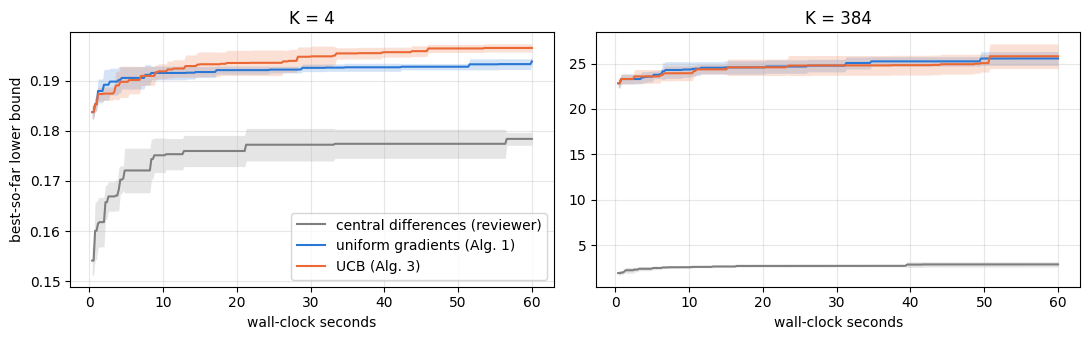

In [7]:
COLORS = {'central differences (reviewer)': '#7f7f7f', 'uniform gradients (Alg. 1)': '#2a78d6', 'UCB (Alg. 3)': '#eb6834'}
grid = np.linspace(0, SECONDS, 300)

def best_at(hist, grid):
    h = np.array(hist)
    idx = np.searchsorted(h[:, 1], grid, side='right') - 1
    return np.where(idx >= 0, h[np.maximum(idx, 0), 2], np.nan)

fig, axes = plt.subplots(1, len(KS), figsize=(5.5 * len(KS), 3.5))
for ax, k in zip(axes, KS):
    for name, rs in runs[k].items():
        curves = np.stack([best_at(r['history'], grid) for r in rs])
        m, s = np.nanmean(curves, 0), np.nanstd(curves, 0)
        ax.plot(grid, m, color=COLORS[name], label=name)
        ax.fill_between(grid, m - s, m + s, color=COLORS[name], alpha=0.2, lw=0)
    ax.set_title(f'K = {k}'); ax.set_xlabel('wall-clock seconds'); ax.grid(alpha=0.3)
axes[0].set_ylabel('best-so-far lower bound')
axes[0].legend(loc='lower right')
plt.tight_layout()
for ext in ('png', 'pdf'):
    fig.savefig(OUT_DIR / f'{TAG}.{ext}', dpi=200, bbox_inches='tight')
plt.show()

In [8]:
lns = {name: m for name, m in model.named_modules() if isinstance(m, nn.LayerNorm)}
EPS = next(iter(lns.values())).eps
captured = {}
handles = [m.register_forward_pre_hook(lambda mod, inp, name=name: captured.__setitem__(name, inp[0][:, -1].std(-1, unbiased=False)))
           for name, m in lns.items()]

torch.manual_seed(0)
tables = {}
with torch.no_grad():
    for k in KS:
        sig = {name: [] for name in lns}
        for _ in range(20):
            nets[k]((2 * torch.rand(BATCH, k, device=device) - 1) * R)
            for name in lns:
                sig[name].append(captured[name])
        sig = {name: torch.cat(s).cpu() for name, s in sig.items()}
        tables[k] = pd.DataFrame({'min sigma': {n: s.min().item() for n, s in sig.items()},
                                  'median sigma': {n: s.median().item() for n, s in sig.items()}})
        tables[k]['min sigma / sqrt(eps)'] = tables[k]['min sigma'] / EPS ** 0.5
        tables[k]['max gamma'] = {n: m.weight.abs().max().item() for n, m in lns.items()}
        tables[k]['gain bound at min sigma'] = tables[k]['max gamma'] / np.sqrt(tables[k]['min sigma'] ** 2 + EPS)
        tables[k]['gain bound at sigma=0'] = tables[k]['max gamma'] / EPS ** 0.5
for h in handles:
    h.remove()
pd.concat(tables, names=['K', 'LayerNorm']).round(4)

min sigma  median sigma  min sigma / sqrt(eps)  max gamma  \
K   LayerNorm                                                                 
4   blocks.0.ln1     1.3856        1.3915               438.1608     1.2235   
    blocks.0.ln2     1.4128        1.4188               446.7644     1.0081   
    blocks.1.ln1     1.2874        1.2931               407.1083     1.3797   
    blocks.1.ln2     1.4272        1.4317               451.3077     1.1153   
    blocks.2.ln1     1.4634        1.4700               462.7597     1.2507   
    blocks.2.ln2     1.6632        1.6749               525.9475     1.2037   
    blocks.3.ln1     1.7448        1.7575               551.7384     1.2078   
    blocks.3.ln2     1.9552        1.9658               618.2808     1.2871   
    blocks.4.ln1     1.8993        1.9094               600.6158     1.2442   
    blocks.4.ln2     2.0569        2.0687               650.4368     1.3202   
    blocks.5.ln1     1.9626        1.9743               620.6403     1.2185   
    blocks.5.ln2     1.9814        1.9942               626.5823     1.3491   
    ln_f             2.3534        2.3637               744.1955     1.2746   
384 blocks.0.ln1     1.4045        1.5051               444.1413     1.2235   
    blocks.0.ln2     1.4253        1.5297               450.7204     1.0081   
    blocks.1.ln1     1.2967        1.4150               410.0442     1.3797   
    blocks.1.ln2     1.3999        1.5213               442.6869     1.1153   
    blocks.2.ln1     1.3941        1.5196               440.8612     1.2507   
    blocks.2.ln2     1.5521        1.6960               490.8160     1.2037   
    blocks.3.ln1     1.5704        1.7439               496.5938     1.2078   
    blocks.3.ln2     1.7609        1.9398               556.8396     1.2871   
    blocks.4.ln1     1.6956        1.8814               536.1808     1.2442   
    blocks.4.ln2     1.8360        2.0265               580.5865     1.3202   
    blocks.5.ln1     1.7434        1.9349               551.2983     1.2185   
    blocks.5.ln2     1.7526        1.9499               554.2100     1.3491   
    ln_f             2.0145        2.2472               637.0340     1.2746   

                  gain bound at min sigma  gain bound at sigma=0  
K   LayerNorm                                                     
4   blocks.0.ln1                   0.8830               386.8948  
    blocks.0.ln2                   0.7135               318.7775  
    blocks.1.ln1                   1.0717               436.2995  
    blocks.1.ln2                   0.7815               352.6925  
    blocks.2.ln1                   0.8546               395.4974  
    blocks.2.ln2                   0.7237               380.6446  
    blocks.3.ln1                   0.6922               381.9323  
    blocks.3.ln2                   0.6583               407.0313  
    blocks.4.ln1                   0.6551               393.4421  
    blocks.4.ln2                   0.6418               417.4760  
    blocks.5.ln1                   0.6209               385.3388  
    blocks.5.ln2                   0.6809               426.6309  
    ln_f                           0.5416               403.0742  
384 blocks.0.ln1                   0.8711               386.8948  
    blocks.0.ln2                   0.7073               318.7775  
    blocks.1.ln1                   1.0640               436.2995  
    blocks.1.ln2                   0.7967               352.6925  
    blocks.2.ln1                   0.8971               395.4974  
    blocks.2.ln2                   0.7755               380.6446  
    blocks.3.ln1                   0.7691               381.9323  
    blocks.3.ln2                   0.7310               407.0313  
    blocks.4.ln1                   0.7338               393.4421  
    blocks.4.ln2                   0.7191               417.4760  
    blocks.5.ln1                   0.6990               385.3388  
    blocks.5.ln2                   0.7698               426.630